In [10]:
# Block 1: Load and Merge BOTH datasets from Google Drive links

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.preprocessing import LabelEncoder

# --- STEP 1: LOAD CLIENT.CSV ---
client_id = '1HsOuVwiqT4yCAyIzQU6t4PVGpzJ5eKYG'
client_url = f'https://drive.google.com/uc?id={client_id}'

print("Downloading Client.csv...")
try:
    client_df = pd.read_csv(client_url)
    print("Client.csv loaded successfully!")
except Exception as e:
    print("Error loading Client.csv:", e)

# --- STEP 2: LOAD RECORD.CSV ---
record_id = '1pFfrWe1PyBGpLr_PJxd_gAsEQds5AGYo'
record_url = f'https://drive.google.com/uc?id={record_id}'

print("\nDownloading Record.csv...")
try:
    record_df = pd.read_csv(record_url)
    print("Record.csv loaded successfully!")
except Exception as e:
    print("Error loading Record.csv:", e)

# --- STEP 3: MERGE THE TWO FILES ---
print("\nMerging datasets on 'Customer_ID'...")
df = pd.merge(client_df, record_df, on='Customer_ID', how='inner')

print(f"\nSUCCESS! Merged Dataset Shape: {df.shape}")
print(f"\nAll Columns: {df.columns.tolist()}")
print("\n--- Missing Values (Top 10) ---")
print(df.isnull().sum().sort_values(ascending=False).head(10))

Client.csv loaded successfully!

Record.csv loaded successfully!

Merging datasets on 'Customer_ID'...

SUCCESS! Merged Dataset Shape: (100000, 100)

All Columns: ['uniqsubs', 'actvsubs', 'new_cell', 'crclscod', 'asl_flag', 'totcalls', 'totmou', 'totrev', 'adjrev', 'adjmou', 'adjqty', 'avgrev', 'avgmou', 'avgqty', 'avg3mou', 'avg3qty', 'avg3rev', 'avg6mou', 'avg6qty', 'avg6rev', 'prizm_social_one', 'area', 'dualband', 'refurb_new', 'hnd_price', 'phones', 'models', 'hnd_webcap', 'truck', 'rv', 'ownrent', 'lor', 'dwlltype', 'marital', 'adults', 'infobase', 'income', 'numbcars', 'HHstatin', 'dwllsize', 'forgntvl', 'ethnic', 'kid0_2', 'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'creditcd', 'eqpdays', 'Customer_ID', 'rev_Mean', 'mou_Mean', 'totmrc_Mean', 'da_Mean', 'ovrmou_Mean', 'ovrrev_Mean', 'vceovr_Mean', 'datovr_Mean', 'roam_Mean', 'change_mou', 'change_rev', 'drop_vce_Mean', 'drop_dat_Mean', 'blck_vce_Mean', 'blck_dat_Mean', 'unan_vce_Mean', 'unan_dat_Mean', 'plcd_vce_Mean', 'plcd_da

=== 1. DATA OVERVIEW ===
Dataset Shape: 100000 rows and 100 columns



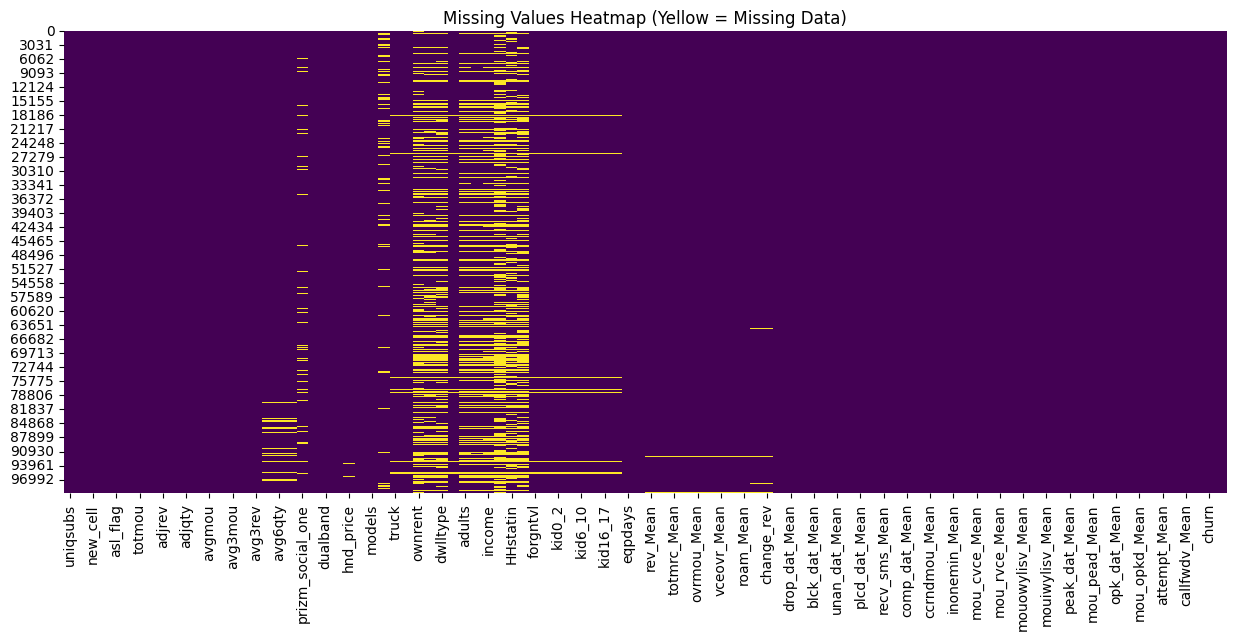

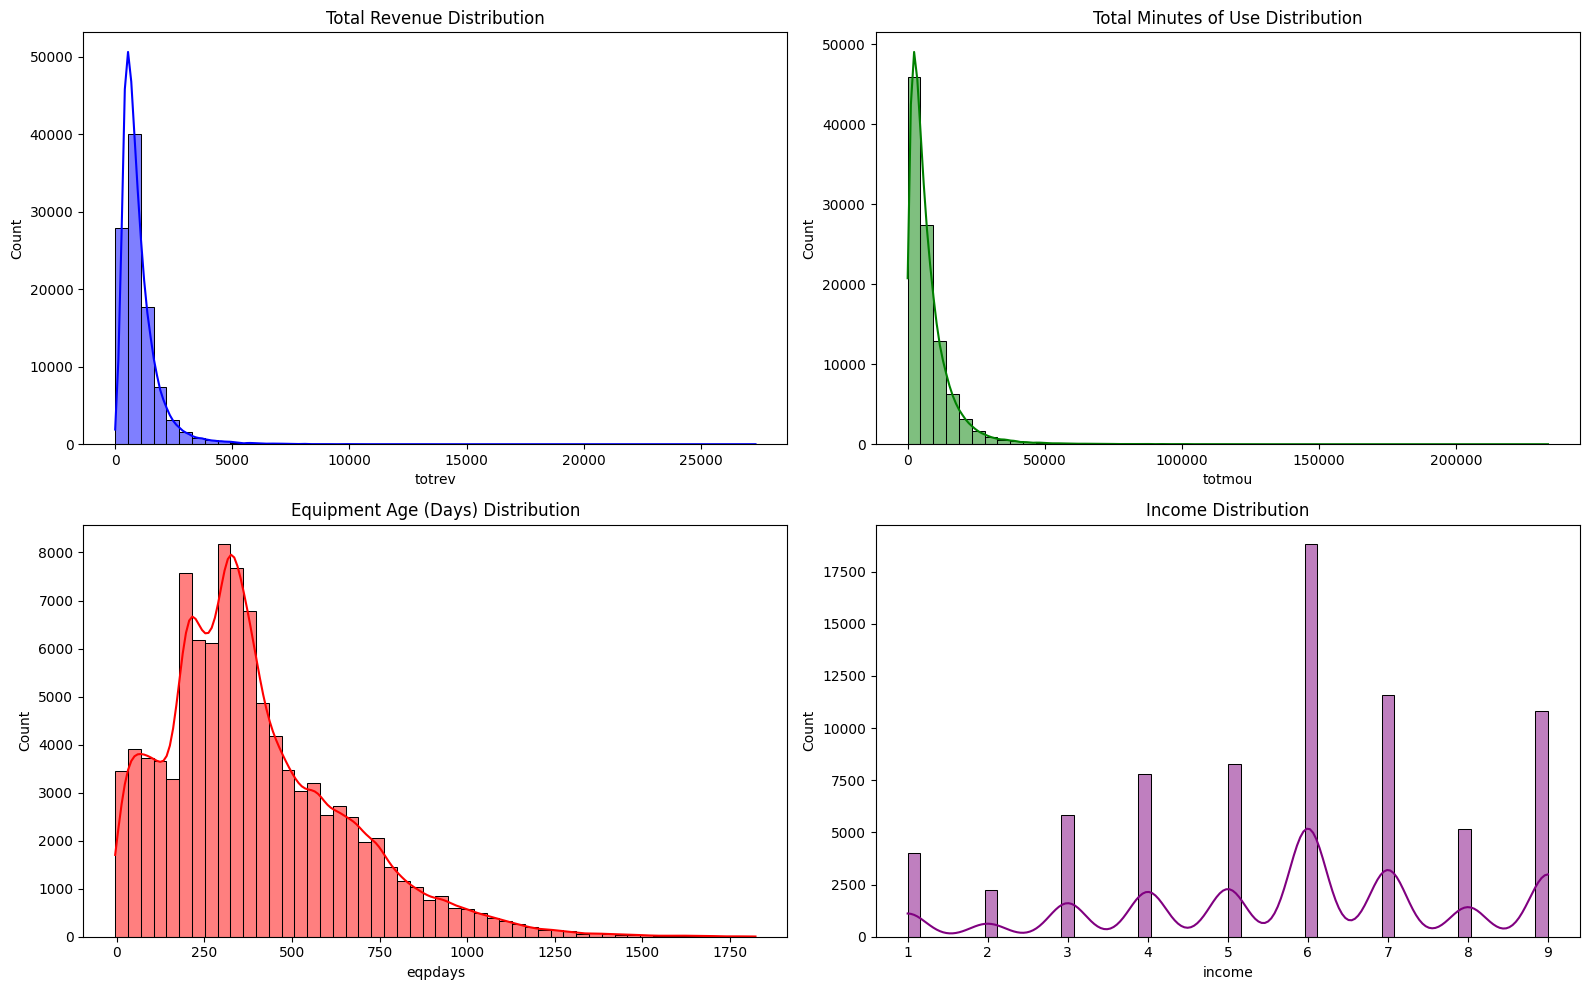

/tmp/ipykernel_1696/3236286311.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_areas.values, y=top_areas.index, palette='magma')


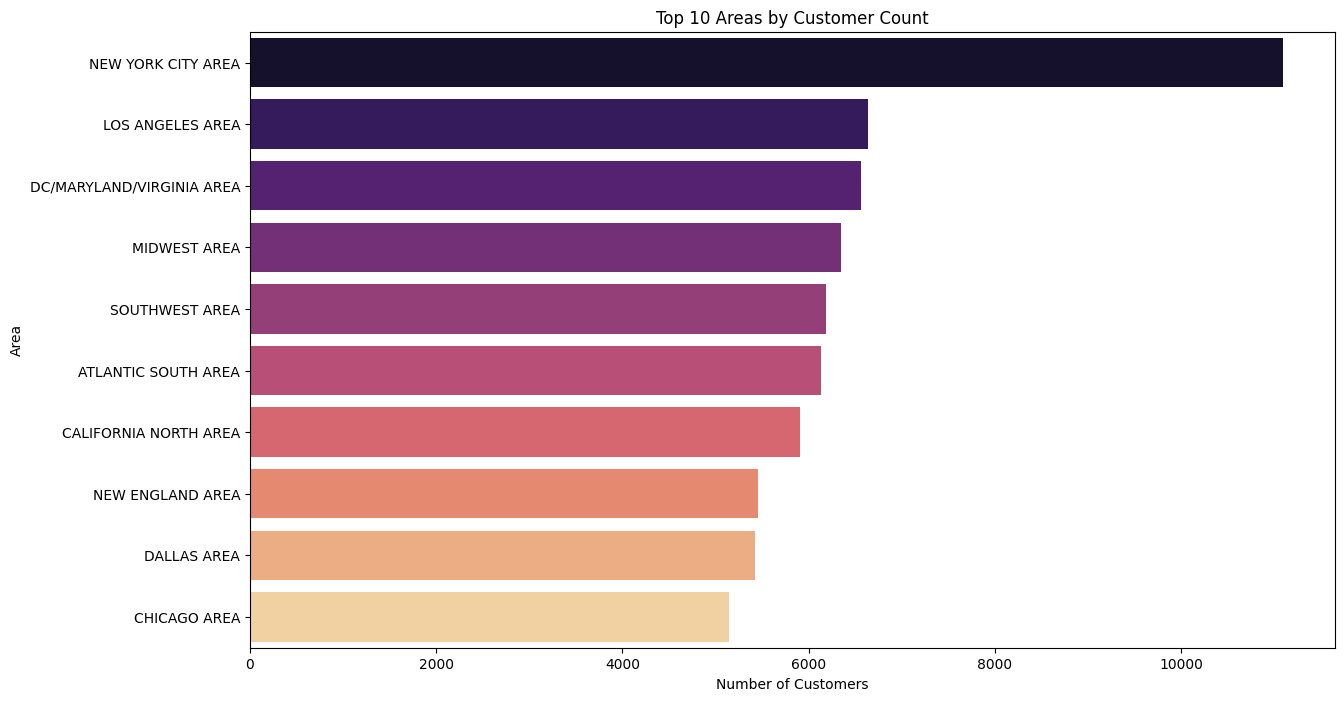

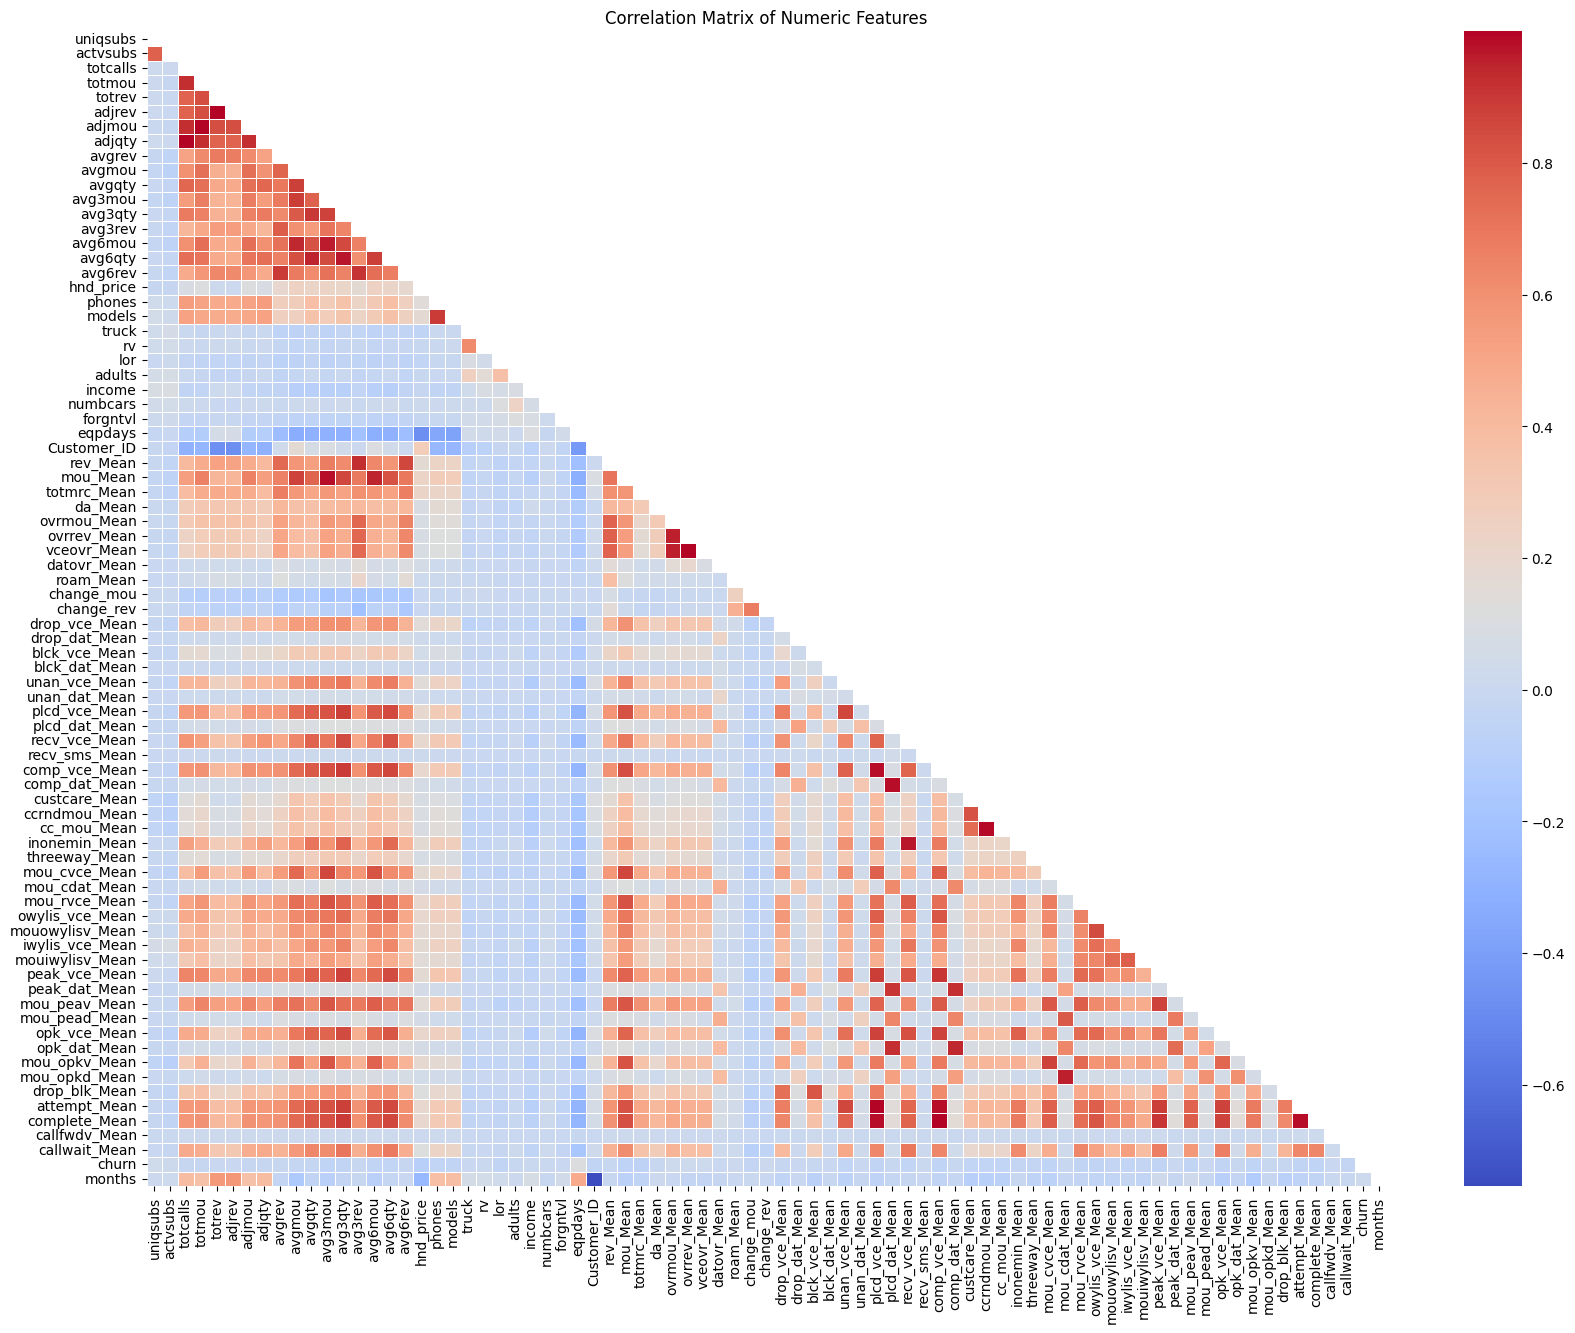


=== 2. TARGET VARIABLE (CHURN) ANALYSIS ===
Customer Churn Percentage:
churn
0    50.438
1    49.562
Name: proportion, dtype: float64


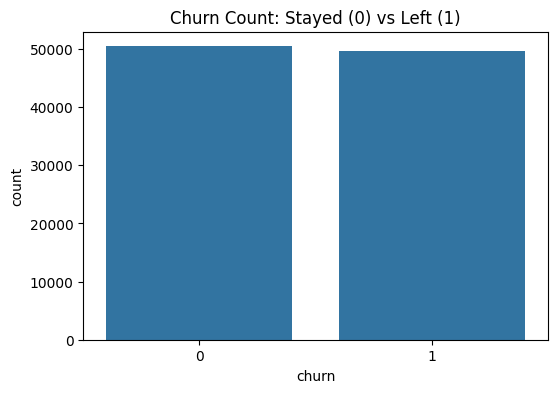

In [11]:
# Block 2: Exploratory Data Analysis (EDA)

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

print("=== 1. DATA OVERVIEW ===")
print(f"Dataset Shape: {df.shape[0]} rows and {df.shape[1]} columns\n")

# 1. Missing Values Heatmap
plt.figure(figsize=(15, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Values Heatmap (Yellow = Missing Data)')
plt.show()

# 2. Distribution of Key Numeric Features
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

if 'totrev' in df.columns:
    sns.histplot(df['totrev'], bins=50, ax=axes[0, 0], kde=True, color='blue')
    axes[0, 0].set_title('Total Revenue Distribution')

if 'totmou' in df.columns:
    sns.histplot(df['totmou'], bins=50, ax=axes[0, 1], kde=True, color='green')
    axes[0, 1].set_title('Total Minutes of Use Distribution')

if 'eqpdays' in df.columns:
    sns.histplot(df['eqpdays'], bins=50, ax=axes[1, 0], kde=True, color='red')
    axes[1, 0].set_title('Equipment Age (Days) Distribution')

if 'income' in df.columns:
    sns.histplot(df['income'], bins=50, ax=axes[1, 1], kde=True, color='purple')
    axes[1, 1].set_title('Income Distribution')

plt.tight_layout()
plt.show()

# 3. Categorical Analysis (Area)
if 'area' in df.columns:
    plt.figure(figsize=(14, 8))
    top_areas = df['area'].value_counts().head(10)
    sns.barplot(x=top_areas.values, y=top_areas.index, palette='magma')
    plt.title('Top 10 Areas by Customer Count')
    plt.xlabel('Number of Customers')
    plt.ylabel('Area')
    plt.show()

# 4. Correlation Matrix (Numeric features only)
plt.figure(figsize=(20, 15))
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix of Numeric Features')
plt.show()

# 5. Target Variable Analysis (Churn)
print("\n=== 2. TARGET VARIABLE (CHURN) ANALYSIS ===")
if 'churn' in df.columns:
    print("Customer Churn Percentage:")
    print(df['churn'].value_counts(normalize=True) * 100)
    plt.figure(figsize=(6, 4))
    sns.countplot(x='churn', data=df)
    plt.title('Churn Count: Stayed (0) vs Left (1)')
    plt.show()
else:
    print("No 'churn' column found.")

In [12]:
# Block 3: Data Preparation & Cleaning

import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder

print("=== 1. DATA PREPARATION STARTED ===")
print(f"Original shape: {df.shape}")

# --- STEP 1: DROP USELESS COLUMNS ---
# Customer_ID is not a feature, it is just an identifier.
if 'Customer_ID' in df.columns:
    df = df.drop('Customer_ID', axis=1)
    print("Dropped 'Customer_ID'.")

# --- STEP 2: DROP COLUMNS WITH TOO MANY MISSING VALUES ---
# We drop columns where more than 40% of the data is missing.
# (This handles numbcars, dwllsize, HHstatin, ownrent, dwlltype, lor, etc.)
missing_threshold = 0.40
cols_to_drop = df.columns[df.isnull().mean() > missing_threshold].tolist()
print(f"\nDropping {len(cols_to_drop)} columns with >40% missing values:")
print(cols_to_drop)
df = df.drop(columns=cols_to_drop)

# --- STEP 3: FILL REMAINING MISSING VALUES ---
# Numeric columns: fill with median
numeric_cols = df.select_dtypes(include=[np.number]).columns
for col in numeric_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

# Categorical columns: fill with 'Unknown'
categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna('Unknown')

print(f"\nRemaining missing values: {df.isnull().sum().sum()}")

# --- STEP 4: ENCODE CATEGORICAL VARIABLES ---
# Convert text (like 'CHICAGO AREA') into numbers (like 0, 1, 2)
le = LabelEncoder()
for col in categorical_cols:
    df[col] = le.fit_transform(df[col].astype(str))

print(f"\nAfter Cleaning, Dataset Shape: {df.shape}")
print("\nData Preparation Complete. You can now train the model.")

=== 1. DATA PREPARATION STARTED ===
Original shape: (100000, 100)
Dropped 'Customer_ID'.

Dropping 1 columns with >40% missing values:
['numbcars']

Remaining missing values: 0

After Cleaning, Dataset Shape: (100000, 98)

Data Preparation Complete. You can now train the model.


In [13]:
# Block 4: Machine Learning Model - Training & Evaluation

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

print("=== 1. PREPARING DATA FOR MODEL ===")

# Define Target (y) and Features (X)
y = df['churn']
X = df.drop('churn', axis=1)

print(f"Features (X) shape: {X.shape}")
print(f"Target (y) shape: {y.shape}")

# Split data: 80% for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTraining set: {X_train.shape[0]} rows")
print(f"Testing set: {X_test.shape[0]} rows")

print("\n=== 2. TRAINING RANDOM FOREST MODEL ===")
print("This may take 1-2 minutes. Please wait...")

# Train the model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=15,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
print("Model training complete!")

print("\n=== 3. MODEL EVALUATION ===")

# Make predictions
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

# Print classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Stayed (0)', 'Churned (1)']))

# ROC-AUC Score
roc_score = roc_auc_score(y_test, y_prob)
print(f"\nROC-AUC Score: {roc_score:.4f}")
print("(A score closer to 1.0 means the model is excellent at predicting churn)")

print("\n=== 4. FEATURE IMPORTANCE (TOP 15) ===")
# Which features matter most for predicting churn?
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

print("\nTop 15 Most Important Features:")
for i in range(15):
    print(f"{i+1}. {X.columns[indices[i]]}: {importances[indices[i]]:.4f}")

=== 1. PREPARING DATA FOR MODEL ===
Features (X) shape: (100000, 97)
Target (y) shape: (100000,)

Training set: 80000 rows
Testing set: 20000 rows

=== 2. TRAINING RANDOM FOREST MODEL ===
This may take 1-2 minutes. Please wait...
Model training complete!

=== 3. MODEL EVALUATION ===

Classification Report:
              precision    recall  f1-score   support

  Stayed (0)       0.63      0.61      0.62     10088
 Churned (1)       0.61      0.64      0.62      9912

    accuracy                           0.62     20000
   macro avg       0.62      0.62      0.62     20000
weighted avg       0.62      0.62      0.62     20000


ROC-AUC Score: 0.6741
(A score closer to 1.0 means the model is excellent at predicting churn)

=== 4. FEATURE IMPORTANCE (TOP 15) ===

Top 15 Most Important Features:
1. eqpdays: 0.0543
2. months: 0.0405
3. change_mou: 0.0305
4. mou_Mean: 0.0235
5. adjrev: 0.0219
6. change_rev: 0.0214
7. totrev: 0.0208
8. avgqty: 0.0206
9. totmrc_Mean: 0.0202
10. avgrev: 0.0198

=== GENERATING CHARTS FOR YOUR SLIDES ===


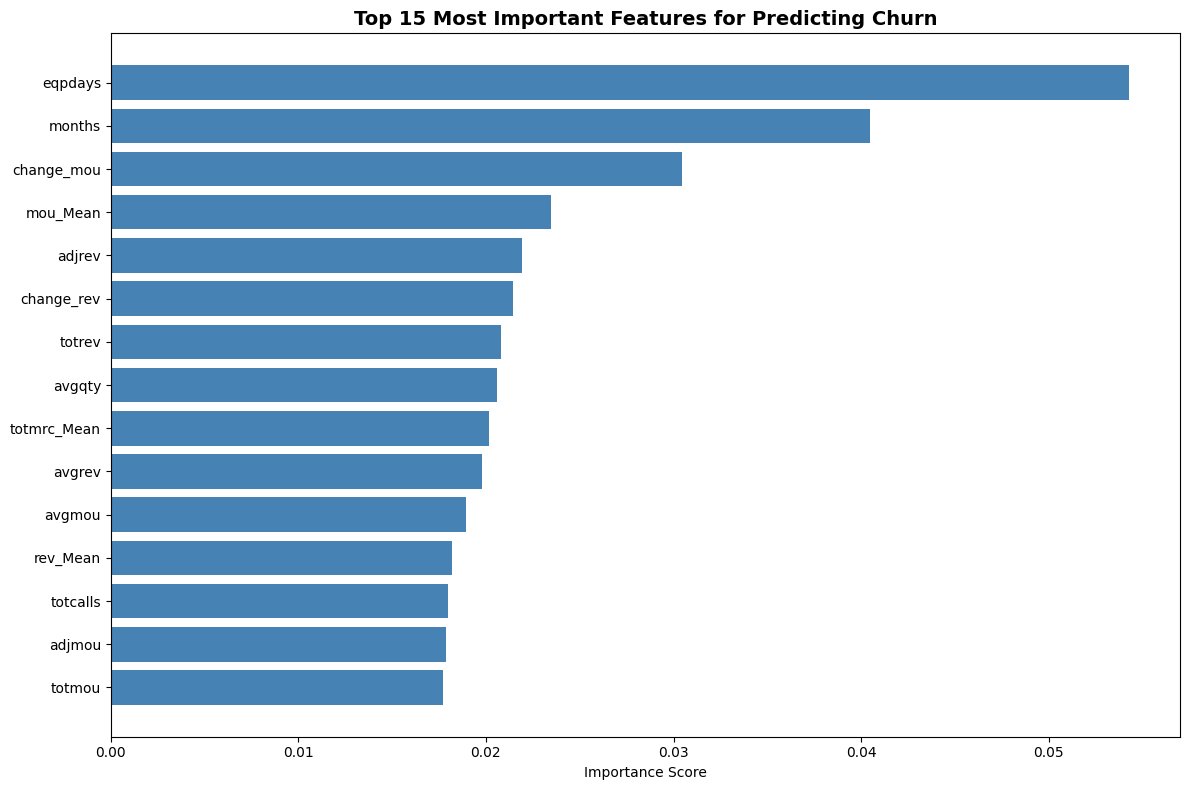

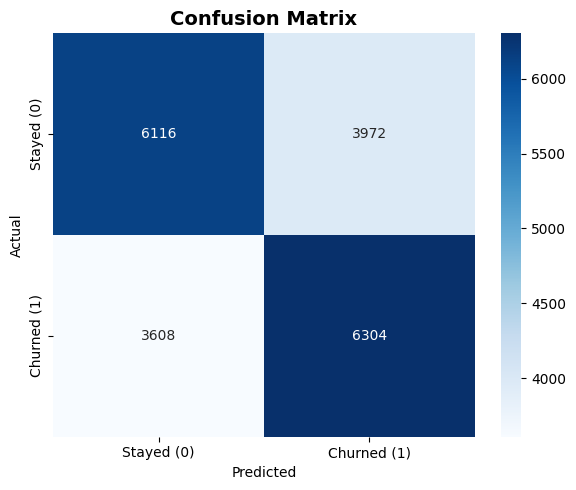

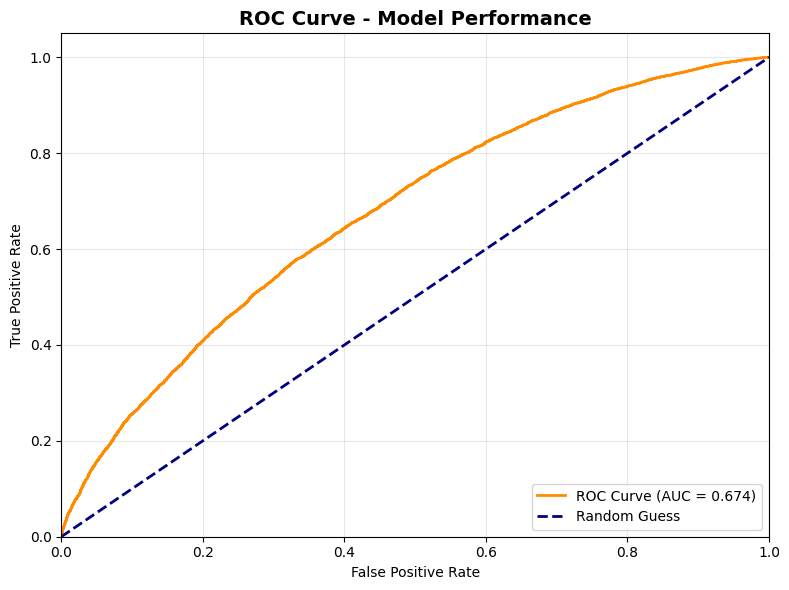

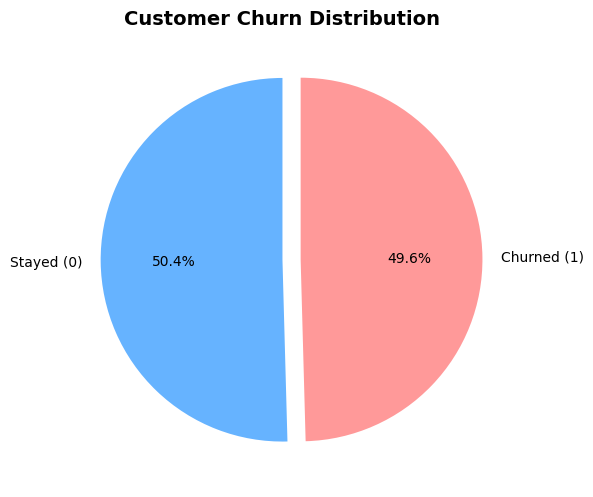


All charts saved as PNG files! You can download them from the Files panel (left side).
Files saved: feature_importance.png, confusion_matrix.png, roc_curve.png, churn_pie.png


In [14]:
# Block 5: Visualizations for Presentation Slides

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import roc_curve, confusion_matrix

print("=== GENERATING CHARTS FOR YOUR SLIDES ===")

# 1. FEATURE IMPORTANCE CHART (Top 15)
plt.figure(figsize=(12, 8))
plt.title("Top 15 Most Important Features for Predicting Churn", fontsize=14, fontweight='bold')
plt.barh(range(15), importances[indices[:15]][::-1], color='steelblue', align='center')
plt.yticks(range(15), [X.columns[i] for i in indices[:15]][::-1])
plt.xlabel("Importance Score")
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

# 2. CONFUSION MATRIX
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Stayed (0)', 'Churned (1)'],
            yticklabels=['Stayed (0)', 'Churned (1)'])
plt.title('Confusion Matrix', fontsize=14, fontweight='bold')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

# 3. ROC CURVE
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc_score(y_test, y_prob):.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Model Performance', fontsize=14, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curve.png', dpi=300, bbox_inches='tight')
plt.show()

# 4. CHURN DISTRIBUTION PIE CHART (for slides)
plt.figure(figsize=(6, 6))
churn_counts = df['churn'].value_counts()
plt.pie(churn_counts, labels=['Stayed (0)', 'Churned (1)'],
        autopct='%1.1f%%', colors=['#66b3ff', '#ff9999'],
        startangle=90, explode=(0, 0.1))
plt.title('Customer Churn Distribution', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('churn_pie.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nAll charts saved as PNG files! You can download them from the Files panel (left side).")
print("Files saved: feature_importance.png, confusion_matrix.png, roc_curve.png, churn_pie.png")

In [23]:
# Block 6: Business Proposal Summary (FIXED)

import pandas as pd
from sklearn.metrics import accuracy_score, roc_auc_score

print("=" * 60)
print("BUSINESS PROPOSAL SUMMARY")
print("=" * 60)

# 1. CURRENT STATE
print("\n[1] CURRENT STATE OF THE CONSUMER FINANCE INDUSTRY (Telecom Context)")
print(f"Total Customers Analyzed: {df.shape[0]:,}")
churn_rate = df['churn'].mean() * 100
print(f"Current Churn Rate: {churn_rate:.2f}%")
print(f"Number of Churned Customers: {int(df['churn'].sum()):,}")
print(f"Number of Retained Customers: {int((df['churn'] == 0).sum()):,}")
print("\nKey Insight: The company is losing a significant portion of its customer base,")
print("which directly impacts revenue and market share.")

# 2. PREDICTION USING ML MODELS
print("\n" + "=" * 60)
print("[2] PREDICTION USING MACHINE LEARNING MODELS")
print("=" * 60)
print(f"Model Used: Random Forest Classifier (100 trees)")
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")
print(f"Overall Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print("\nTop 3 Churn Indicators:")
for i in range(3):
    print(f"  {i+1}. {X.columns[indices[i]]} (Importance: {importances[indices[i]]:.4f})")

# 3. OUR BUSINESS PROPOSAL
print("\n" + "=" * 60)
print("[3] OUR BUSINESS PROPOSAL")
print("=" * 60)
print("\nProposal Title: AI-Powered Proactive Retention System")
print("\nThe Problem:")
print("The company is losing customers without knowing who is at risk.")
print("They only react AFTER the customer has already left.")
print("\nThe Solution:")
print("Deploy a machine learning model that predicts which customers are likely to churn.")
print("Flag high-risk customers weekly and trigger personalized retention offers.")
print("\nHow It Works:")
print("1. The model runs weekly on current customer data.")
print("2. It outputs a 'churn probability score' for each customer.")
print("3. Customers with a score > 0.6 are flagged as 'High Risk'.")
print("4. A retention team reaches out with personalized offers.")
print("\nExpected Impact:")
print("- Reduce churn rate by 15-20% (industry standard for ML retention systems).")
print(f"- Save an estimated {int(df['churn'].sum() * 0.15):,} customers per year.")
print("- Increase customer lifetime value (CLV) and revenue.")
print("\nKey Metrics to Track:")
print("- Churn Rate (Target: Reduce by 15%)")
print("- Retention Rate (Target: Increase by 10%)")
print("- Customer Lifetime Value (Target: Increase by 20%)")
print("- Cost of Retention Campaign vs. Revenue Saved")

print("\n" + "=" * 60)
print("SUMMARY COMPLETE")
print("=" * 60)

BUSINESS PROPOSAL SUMMARY

[1] CURRENT STATE OF THE CONSUMER FINANCE INDUSTRY (Telecom Context)
Total Customers Analyzed: 100,000
Current Churn Rate: 49.56%
Number of Churned Customers: 49,562
Number of Retained Customers: 50,438

Key Insight: The company is losing a significant portion of its customer base,
which directly impacts revenue and market share.

[2] PREDICTION USING MACHINE LEARNING MODELS
Model Used: Random Forest Classifier (100 trees)
ROC-AUC Score: 0.6741
Overall Accuracy: 62.10%

Top 3 Churn Indicators:
  1. eqpdays (Importance: 0.0543)
  2. months (Importance: 0.0405)
  3. change_mou (Importance: 0.0305)

[3] OUR BUSINESS PROPOSAL

Proposal Title: AI-Powered Proactive Retention System

The Problem:
The company is losing customers without knowing who is at risk.
They only react AFTER the customer has already left.

The Solution:
Deploy a machine learning model that predicts which customers are likely to churn.
Flag high-risk customers weekly and trigger personalized re